# Practical

## Estimating R0 from the final size of an epidemic

The final proportion of a population infected and the basic reproductive number are related through the following equation:

<center>$ r(\infty) = 1 - e^{(- R_0 r(\infty))}$.  </center>


To solve for R0 given a final size we can simply plug in our observed final size and rearrange the equation as shown below.

<center>$ R_0 = - \frac{ln(1-r(\infty))}{r(\infty)} $.  </center>

### Question 1:
Write a function called my_R0 that takes a value of r(∞) (the final epidemic size) and returns an estimated R0 based on the above relationship.


In [3]:
import math
import numpy as np
from scipy.optimize import minimize_scalar
from functools import partial


def my_R0(rfi ):
    x = - np.log(1-rfi)/rfi
    return x



Using this function we can estimate the reproductive number for diseases from different outbreak investigations. The table below has the proportion of individuals infected from a number of published outbreak investigations in closed(ish) populations. Use your function ‘my_R0’ to estimate the final epidemic size for each outbreak.

### Question 2:
Use your function _my_R0_ to estimate R0 for each of the following two outbreaks.   

| Disease | Proportion Infected | Source |
| --- | --- | --- |
| H1N1 Influenza | 0.24 | Lessler et al, 2009  |
| Measles | 0.77  | Panum, 1847 |


In [4]:
# Code here
R0_1 = my_R0(0.24)
R0_2 = my_R0(0.77)

print(R0_1)
print(R0_2)

1.143486857090668
1.9086700909856384



### Question 3:
From a serological study of past exposure (IgG) for measles, the estimated proportion infected was 0.65 with a standard deviation of 0.2. Use a distribution of these values to re-estimate possible values of R0. To sample values of R0 from a normal distribution you can use np.random.normal. Plot the response as a histogram. Why might these values be different the one provided in the table in Question 2?

(array([ 5., 23., 15., 11.,  9.,  8.,  8.,  5.,  1.,  1.,  1.,  1.,  1.,
         1.,  0.,  1.,  2.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  1.]),
 array([1.11142482, 1.25723512, 1.40304541, 1.54885571, 1.694666  ,
        1.8404763 , 1.98628659, 2.13209689, 2.27790718, 2.42371748,
        2.56952777, 2.71533807, 2.86114836, 3.00695866, 3.15276895,
        3.29857925, 3.44438954, 3.59019984, 3.73601013, 3.88182043,
        4.02763072, 4.17344102, 4.31925131, 4.46506161, 4.6108719 ,
        4.7566822 , 4.90249249, 5.04830279, 5.19411308, 5.33992338,
        5.48573367]),
 <BarContainer object of 30 artists>)

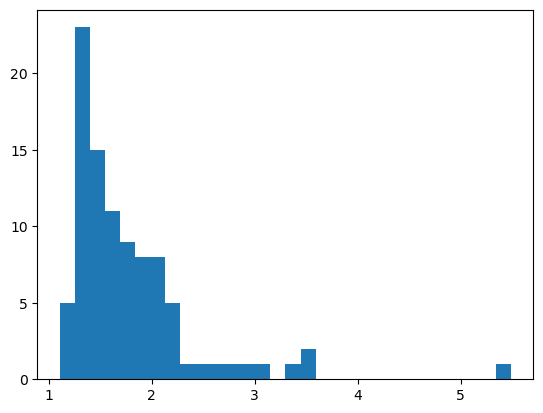

In [18]:
# Code here
import matplotlib.pyplot as plt

rfi = np.random.normal(0.65, 0.2, 100)

R0 = ()
for i in rfi:
    if i < 1:
        R = my_R0(i)
        R0 = R0 + (R,)

counts, bins = np.histogram(R0,bins=30)
plt.hist(bins[:-1], bins, weights=counts)

### Question 4:
Next, let's estimate the final size of an epidemic for a given value of R0

To do this, we need to solve the equation above for r(∞) using an iterative method. Start by writing an objective function that takes an value of r(∞) and R0 as inputs and returns the absolute difference between the right and left hand sides of the equation above. We will want to minimize this value (i.e. the smallest difference between the right side and left sides of the equation). Try three candidate values for r_inf of 0.2, 0.4, 0.6, with an R0 of 1.1 - which is the closest to the optimal?



In [20]:

def objective_function(r_inf, R0):
    R = my_R0(r_inf)
    d = np.abs(R0-R)
    return (d)

r_inf_test_1 = 0.2
r_inf_test_2 = 0.4
r_inf_test_3 = 0.6

print(objective_function(r_inf_test_1, 1.1))
print(objective_function(r_inf_test_2, 1.1))
print(objective_function(r_inf_test_3, 1.1))

0.015717756571048458
0.1770640594149766
0.4271512197902583


Let’s then try to figure out if we can solve for r(∞) when R0=1.1. To calculate this, we can use a function to find the optimized value, called minimize_scalar(func, bounds=(0, 1),method="bounded"), where func is the function to be minimized.

In [21]:
fixed_R0 = 1.1
obj_f_partial = partial(objective_function, R0=fixed_R0)
res = minimize_scalar(obj_f_partial, bounds=(0, 1),method="bounded")

print(res,"\n")
print("minima : %.7f" %res.x)


 message: Solution found.
 success: True
  status: 0
     fun: 1.0574453903622327e-06
       x: 0.17613578043881675
     nit: 19
    nfev: 19 

minima : 0.1761358


### Question 5:
The estimated R0 for measles follows a normal distribution with a mean of 15, standard deviation of 4. Estimate 1000 final sizes of the outbreak given this distribution of R0 values. Present results as a histogram.

(array([  3.,  13.,  47., 129., 222., 240., 195., 106.,  32.,  13.]),
 array([ 1.42743861,  3.95960408,  6.49176955,  9.02393501, 11.55610048,
        14.08826594, 16.62043141, 19.15259687, 21.68476234, 24.2169278 ,
        26.74909327]),
 <BarContainer object of 10 artists>)

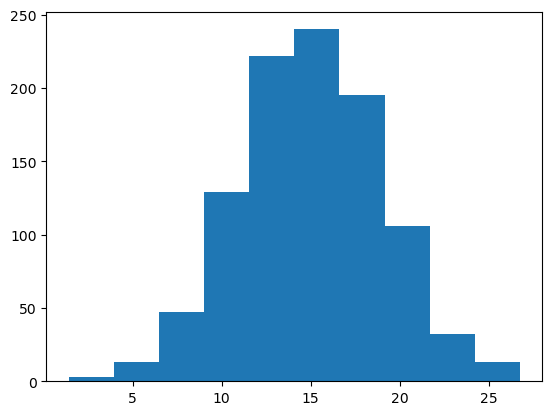

In [22]:
# Code here
R0 = np.random.normal(15, 4, 1000)
counts, bins = np.histogram(R0)
plt.hist(bins[:-1], bins, weights=counts)

## Numerically solving SIR models

We will introduce code to numerically integrate SIR models. We will use scipy.integrate.

### Question 6:
Create an SIR function, that returns dS, dI and dR for a given set of beta, gamma, and population size inputs (use a vector 'y' that has three slots representing the starting sizes of the S, I and R populations.

Next, create a run_sir_function that numerically integrates using the sir_function as an input. The key function will be solve_ivp. The method you need is 'LSODA'.  For the time points to conduct the numerical intergartion use a max_time of 365 days.Add an option for frequency dependent transmission.

There are some hints for the code below.

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def sir_function(t, y, beta, gamma):
    S, I, R = y
    dS = - beta*S*I
    dI = beta*S*I - gamma*I
    dR = gamma*I
    return(dS, dI, dR)


def run_sir_model(beta,gamma,initial_state, max_time, freq_dependent):

  if freq_dependent == True:
    beta_divisor = sum(initial_state)
  else:
    beta_divisor = 1
  
  beta = beta/beta_divisor
  y = initial_state

  sir_output = solve_ivp(sir_function, [0, max_time], initial_state, args=(beta, gamma), method='LSODA')

  return(sir_output)



## Question 7:

We can then use this code to numerically integrate an SIR model with fixed parameters. Use the code above to identify R0 in this model using frequency dependent transmission? Use an initial state of S=500000, I = 1, R = 10000 a gamma of 0.05 and a beta of 1. Plot the resulting curves of S, I and R.


  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  3.402e-02 ...  3.588e+02  3.650e+02]
        y: [[ 5.000e+05  5.000e+05 ...  1.520e-03  1.520e-03]
            [ 1.000e+00  1.033e+00 ...  1.654e-02  1.216e-02]
            [ 1.000e+04  1.000e+04 ...  5.100e+05  5.100e+05]]
      sol: None
 t_events: None
 y_events: None
     nfev: 279
     njev: 0
      nlu: 0


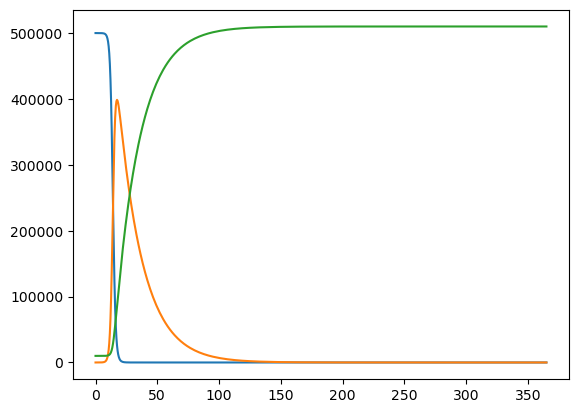

In [45]:
# Code here
initial_state = [500000, 1, 10000]
beta = 1
gamma = 0.05
max_time = 365

M = run_sir_model(beta,gamma,initial_state, max_time, freq_dependent=True)
print(M)

print(plt.plot(M.t, M.y[0]))
print(plt.plot(M.t, M.y[1]))
print(plt.plot(M.t, M.y[2]))


## Question 8:
Run two more simulations – one with a higher beta of 2, and one with a lower beta of 0.5. All other parameters and states should be the same as above. Plot the output from these simulations on the same plot. Describe the how these two epidemics differ. Why would a different beta value result in a different epidemic?

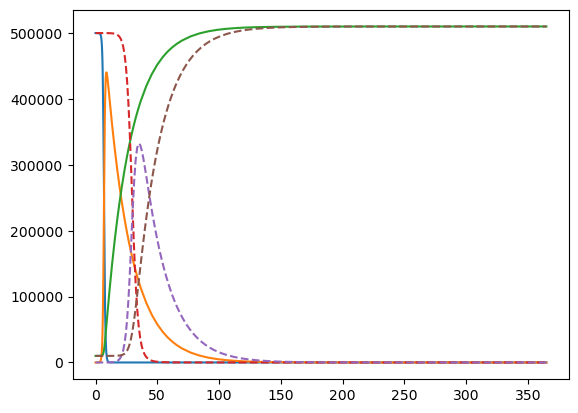

In [46]:
# Code here
initial_state = [500000, 1, 10000]
beta1 = 2
beta2 = 0.5
gamma = 0.05
max_time = 365

M1 = run_sir_model(beta1,gamma,initial_state, max_time, freq_dependent=True)
M2 = run_sir_model(beta2,gamma,initial_state, max_time, freq_dependent=True)

plt.plot(M1.t, M1.y[0])
plt.plot(M1.t, M1.y[1])
plt.plot(M1.t, M1.y[2])

plt.plot(M2.t, M2.y[0], linestyle='dashed')
plt.plot(M2.t, M2.y[1], linestyle='dashed')
plt.plot(M2.t, M2.y[2], linestyle='dashed')

smaller beta: slower onset of epidemic (becaues smaller transmission rate)
, lesser people infected


## Question 9:
What’s the mean recovery time for an infected individual?


## Question 10:
Suppose there is a pathogen whose transmission can be approximated with an SIR model where beta = 1, gamma = 1/10. There is a new intervention in place that would reduce the transmissibility of the pathogen by half. Assume frequency dependent transmission and the same initial conditions as above. Run two simulations (and plot the results) - one with the intervention and one without. What are the main differences between these two scenarios? Justify which parameters and/or compartments you changed and why.


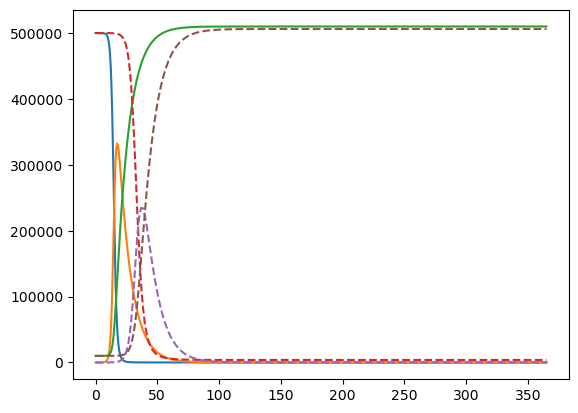

In [47]:
# Code here
initial_state = [500000, 1, 10000]
beta1 = 1
beta2 = 0.5 #intervention reduce transmissibility by half
gamma = 0.1
max_time = 365

M1 = run_sir_model(beta1,gamma,initial_state, max_time, freq_dependent=True)
M2 = run_sir_model(beta2,gamma,initial_state, max_time, freq_dependent=True)

plt.plot(M1.t, M1.y[0])
plt.plot(M1.t, M1.y[1])
plt.plot(M1.t, M1.y[2])

plt.plot(M2.t, M2.y[0], linestyle='dashed')
plt.plot(M2.t, M2.y[1], linestyle='dashed')
plt.plot(M2.t, M2.y[2], linestyle='dashed')



## Question 11:
Adapt the code from Question 6 to incorporate vaccination – where the vaccine results in perfect protection from infection. Run the model with a 10% vaccination rate and plot the resulting number of infected individuals over time in both a scenario with no vaccination and one with vaccination. How many infections were prevented through the vaccine?

In [48]:
# Code here

def sir_function1(t, y, beta, gamma, phi):
    S, I, R = y
    dS = - beta*S*I - phi*S
    dI = beta*S*I - gamma*I
    dR = gamma*I +phi*S
    return(dS, dI, dR)


def run_sir_model1(beta,gamma, phi, initial_state, max_time, freq_dependent):

  if freq_dependent == True:
    beta_divisor = sum(initial_state)
  else:
    beta_divisor = 1
  
  beta = beta/beta_divisor
  y = initial_state

  sir_output = solve_ivp(sir_function1, [0, max_time], initial_state, args=(beta, gamma, phi), method='LSODA')

  return(sir_output)

infections prevented through vaccination396230


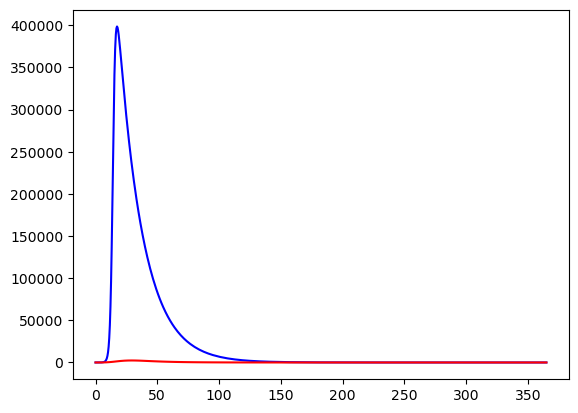

In [67]:
initial_state = [500000, 1, 10000]
beta = 1
gamma = 0.05
phi = 0.1
max_time = 365

M_no = run_sir_model1(beta,gamma,0,initial_state, max_time, freq_dependent=True)
M_vac = run_sir_model1(beta,gamma,phi,initial_state, max_time, freq_dependent=True)

print(plt.plot(M_no.t, M_no.y[1], color='blue'))
print(plt.plot(M_vac.t, M_vac.y[1], color='r'))
print(f'infections prevented through vaccination{int(max(M_no.y[1])-max(M_vac.y[1]))}')


### End of doc